# Airbnbs & Gentrification in New Orleans

**Live project:** https://sinamayer.github.io/nola_airbnb/

This notebook builds every map in the project. It aggregates Inside Airbnb listings to census tracts, computes an Airbnb affordability ratio (median nightly price relative to median daily household income), flags tracts with unreliable income estimates, overlays the rental housing gap with FEMA flood zones, and builds an interactive Folium webmap with transit access.

*Final project for Command-Line GIS, Bloustein School, Rutgers University (Fall 2025). Author: Sina-Marie Mayer.*

**Outputs:** `airbnb_affordability_map.png`, `airbnb_housinggap_map.png`, `nola_Airbnbs.html`

## Data sources

*   Airbnb listings: https://insideairbnb.com/get-the-data/ (`listings.csv`, New Orleans)
*   Census tract boundaries (2020): https://www.nhgis.org/
*   Median household income: ACS 2023 5-year estimates via the Census API
*   Neighborhoods: https://data.nola.gov/Geographic-Base-Layers/Neighborhood-Statistical-Areas/c2j2-5qdf/about_data
*   Rental housing gap: https://www.policymap.com/data/moodys-housing-shortfall
*   FEMA flood zones: https://msc.fema.gov/portal/home
*   RTA routes: https://catalog.data.gov/dataset/truck-routes-fcf7e
*   RTA stops: https://data.nola.gov/Transportation-and-Infrastructure/RTA-Stops/hp2r-gr3h/about_data

## How to run

1. Download the files above into a `data/` folder next to this notebook (raw data is not included in the repo).
2. Optional: set a free Census API key as the environment variable `CENSUS_API_KEY`.
3. Install the packages in `requirements.txt` and run all cells. The notebook also runs in Google Colab.


# Setup

In [ ]:
# Install dependencies (needed in Colab; locally use: pip install -r requirements.txt)
!pip install geopandas mapclassify contextily census folium


In [4]:
import os

import numpy as np
import pandas as pd
import geopandas as gpd
from shapely import wkt
from shapely.geometry import Point

import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import matplotlib.patches as mpatches
import contextily as ctx

import folium
from folium import plugins
from census import Census

plt.rcParams["figure.figsize"] = (10, 10)  # default plot size


In [ ]:
# File locations: works locally (data/ folder) and in Google Colab (Google Drive)
try:
    from google.colab import drive
    drive.mount('/drive')
    PROJECT_DIR = "/drive/My Drive/595 - Command-Line GIS/Final Project"
except ImportError:
    PROJECT_DIR = "."

DATA_DIR = os.path.join(PROJECT_DIR, "Data" if PROJECT_DIR != "." else "data")
OUTPUT_DIR = PROJECT_DIR


# Import Airbnb Data

In [6]:
nola_airbnbs_df = pd.read_csv(os.path.join(DATA_DIR, 'listings.csv'))

# convert to geodataframe
nola_airbnbs = gpd.GeoDataFrame(
    nola_airbnbs_df,
    geometry=gpd.points_from_xy(nola_airbnbs_df["longitude"], nola_airbnbs_df["latitude"]),
    crs="EPSG:4326"
)
nola_airbnbs.head()

,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365,number_of_reviews_ltm,license,geometry
0,19091,Fully Furnished Cozy Apartment,72880,John,NaN,Leonidas,29.96100,-90.11950,Entire home/apt,61.0,1,510,2025-08-31,2.72,1,331,7,"25-NSTR-11772, 25-OSTR-11151",POINT (-90.1195 29.961)
1,71624,Ravenwood Manor (Historic Bywater),367223,Susan,NaN,Bywater,29.96153,-90.04364,Entire home/apt,150.0,30,316,2025-05-07,1.78,1,356,7,"21-RSTR-18609, 22-OSTR-20720",POINT (-90.04364 29.96153)
2,74498,Maison Marais 1,391462,Georgia,NaN,St. Roch,29.96986,-90.05172,Entire home/apt,85.0,3,662,2025-06-29,3.75,3,231,28,23-XSTR-13082,POINT (-90.05172 29.96986)
3,79536,FeelAtHomeInNewOrleans-PrivateApt,428362,Miriam,NaN,Seventh Ward,29.97803,-90.07450,Entire home/apt,NaN,3,799,2025-09-04,4.57,1,0,68,"23-NSTR-15067, 24-OSTR-20882",POINT (-90.0745 29.97803)
4,79609,Bywater's Original & Finest,428909,Stephen,NaN,St. Claude,29.96448,-90.03667,Entire home/apt,84.0,30,505,2025-03-05,2.86,1,291,3,"23-ISTR-02823, 23-OSTR-02823",POINT (-90.03667 29.96448)


# Import Tract Geometries

<Axes: >

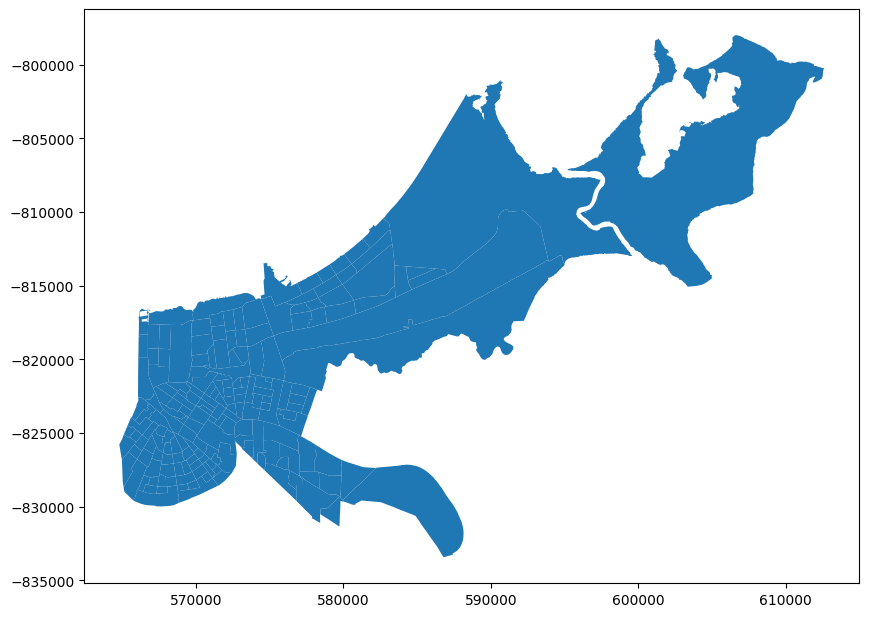

In [7]:
# import NOLA census tracts
gdf_tracts = gpd.read_file(os.path.join(DATA_DIR, 'nhgis_tract_2020.zip'))

nola_gdf_tracts = gdf_tracts[gdf_tracts["STATEFP"] == "22"]
nola_parishes = ["071"]
nola_tracts = nola_gdf_tracts[nola_gdf_tracts["COUNTYFP"].isin(nola_parishes)]

nola_tracts.plot()

# Import Neighborhood Boundaries

In [8]:
nola_neighborhoods_df = pd.read_csv(os.path.join(DATA_DIR, 'Neighborhood_Statistical_Area.csv'))

# convert WKT strings to shapely geometry
nola_neighborhoods_df["geometry"] = nola_neighborhoods_df["the_geom"].apply(wkt.loads)

# convert to geodataframe
nola_neighborhoods = gpd.GeoDataFrame(
    nola_neighborhoods_df,
    geometry="geometry",
    crs="EPSG:4326"
)

nola_neighborhoods.head()

,the_geom,OBJECTID,GNOCDC_LAB,LUP_LAB,NEIGH_ID,Shape.STArea(),Shape.STLength(),geometry
0,MULTIPOLYGON (((-90.08520761668 29.95045741323...,6,B. W. COOPER,B. W. COOPER HOUSING DEV,12D,8.808477e+06,12118.012710,"MULTIPOLYGON (((-90.08521 29.95046, -90.0855 2..."
1,MULTIPOLYGON (((-90.006211734764 29.9581247205...,32,HOLY CROSS,HOLY CROSS,15C,2.699961e+07,21187.180303,"MULTIPOLYGON (((-90.00621 29.95812, -90.01204 ..."
2,MULTIPOLYGON (((-90.078181615336 29.9759974189...,7,BAYOU ST. JOHN,BAYOU ST. JOHN,5D,1.150536e+07,15653.798585,"MULTIPOLYGON (((-90.07818 29.976, -90.07868 29..."
3,MULTIPOLYGON (((-90.056984610232 29.9687144176...,57,SEVENTH WARD,SEVENTH WARD,6B,3.260530e+07,23675.658756,"MULTIPOLYGON (((-90.05698 29.96871, -90.05814 ..."
4,MULTIPOLYGON (((-90.035429604547 29.9837954212...,24,FLORIDA AREA,FLORIDA AREA,8B,8.781458e+06,15567.623832,"MULTIPOLYGON (((-90.03543 29.9838, -90.03546 2..."


<Axes: >

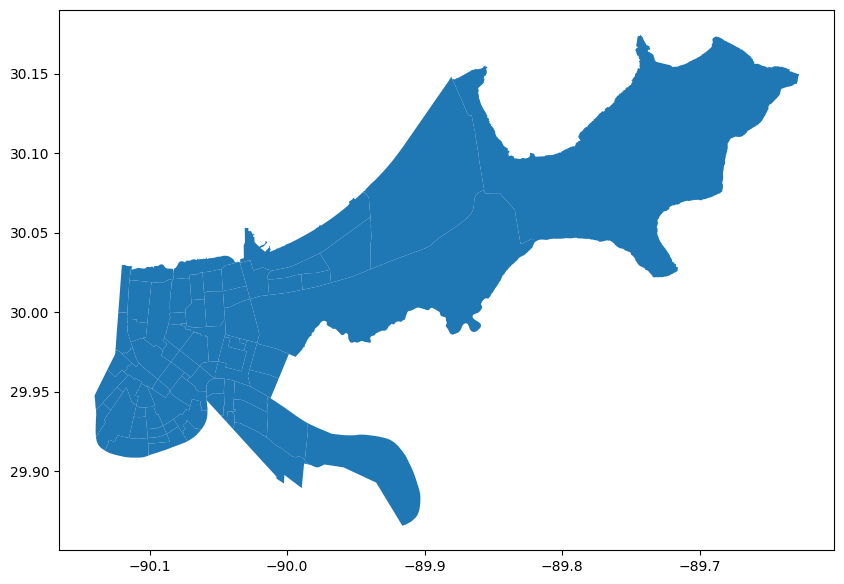

In [9]:
nola_neighborhoods.plot()

In [10]:
nola_neighborhoods_lasp = nola_neighborhoods.to_crs(epsg=3452)

# Spatial Join Airbnbs to Tracts

First: polygon -> point

In [11]:
# project dataframes to locally appropriate CRS
nola_airbnbs_lasp = nola_airbnbs.to_crs(epsg=3452)
nola_tracts_lasp = nola_tracts.to_crs(epsg=3452)

In [12]:
print(nola_airbnbs_lasp.shape)
print(nola_tracts_lasp.shape)

(7444, 19)
(183, 16)


In [13]:
# spatial join
nola_airbnb_with_tracts_lasp = nola_airbnbs_lasp.sjoin(nola_tracts_lasp, how="inner")

In [14]:
nola_airbnb_with_tracts_lasp.shape

(7439, 35)

In [15]:
nola_airbnb_with_tracts_lasp.head()

,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,...,NAME,NAMELSAD,MTFCC,FUNCSTAT,ALAND,AWATER,INTPTLAT,INTPTLON,Shape_Leng,Shape_Area
0,19091,Fully Furnished Cozy Apartment,72880,John,NaN,Leonidas,29.96100,-90.11950,Entire home/apt,61.0,...,132,Census Tract 132,G5020,S,930277.0,46420.0,+29.9582153,-090.1252417,5157.525658,9.766952e+05
1,71624,Ravenwood Manor (Historic Bywater),367223,Susan,NaN,Bywater,29.96153,-90.04364,Entire home/apt,150.0,...,12,Census Tract 12,G5020,S,732101.0,367648.0,+29.9622293,-090.0464417,4433.316032,1.099747e+06
2,74498,Maison Marais 1,391462,Georgia,NaN,St. Roch,29.96986,-90.05172,Entire home/apt,85.0,...,19,Census Tract 19,G5020,S,398501.0,0.0,+29.9714928,-090.0533552,2583.287009,3.985028e+05
3,79536,FeelAtHomeInNewOrleans-PrivateApt,428362,Miriam,NaN,Seventh Ward,29.97803,-90.07450,Entire home/apt,NaN,...,36,Census Tract 36,G5020,S,385316.0,0.0,+29.9781089,-090.0736169,2729.542742,3.853171e+05
4,79609,Bywater's Original & Finest,428909,Stephen,NaN,St. Claude,29.96448,-90.03667,Entire home/apt,84.0,...,136,Census Tract 136,G5020,S,296774.0,0.0,+29.9655765,-090.0357242,2198.040360,2.967710e+05


Now: point -> polygon

In [16]:
# Airbnb density
airbnbs_per_tract = nola_airbnb_with_tracts_lasp.groupby("GEOID").size().reset_index(name="airbnb_count")

# median nightly price
median_price_per_tract = nola_airbnb_with_tracts_lasp.groupby("GEOID")["price"].median().reset_index(name="median_price")

# combine counts and median prices
airbnb_stats = airbnbs_per_tract.merge(median_price_per_tract, on="GEOID")

airbnb_stats.head()

,GEOID,airbnb_count,median_price
0,22071000100,52,123.0
1,22071000200,33,103.0
2,22071000300,8,84.0
3,22071000400,24,117.0
4,22071000601,1,NaN


In [17]:
# merge back with tract polygons
nola_tracts_with_airbnb_stats = nola_tracts_lasp.merge(airbnb_stats, on="GEOID", how="left")

nola_tracts_with_airbnb_stats.head()

,GISJOIN,STATEFP,COUNTYFP,TRACTCE,GEOID,NAME,NAMELSAD,MTFCC,FUNCSTAT,ALAND,AWATER,INTPTLAT,INTPTLON,Shape_Leng,Shape_Area,geometry,airbnb_count,median_price
0,G2200710000100,22,071,000100,22071000100,1,Census Tract 1,G5020,S,717245.0,505586.0,+29.9532061,-090.0521978,4606.405929,1.222833e+06,"POLYGON ((3688472.899 529109.107, 3688179.32 5...",52.0,123.0
1,G2200710000200,22,071,000200,22071000200,2,Census Tract 2,G5020,S,499389.0,167245.0,+29.9459372,-090.0528397,4055.663337,6.666407e+05,"POLYGON ((3688472.899 529109.107, 3688772.924 ...",33.0,103.0
2,G2200710000300,22,071,000300,22071000300,3,Census Tract 3,G5020,S,634745.0,0.0,+29.9409498,-090.0489913,3610.964402,6.347467e+05,"POLYGON ((3688005.861 524073.788, 3687642.796 ...",8.0,84.0
3,G2200710000400,22,071,000400,22071000400,4,Census Tract 4,G5020,S,1496645.0,200524.0,+29.9468233,-090.0425280,7749.801050,1.697170e+06,"POLYGON ((3689882.872 532343.56, 3690994.424 5...",24.0,117.0
4,G2200710000601,22,071,000601,22071000601,6.01,Census Tract 6.01,G5020,S,485434.0,0.0,+29.9327828,-090.0409526,2916.366439,4.854390e+05,"POLYGON ((3690075.304 525108.099, 3690223.328 ...",1.0,NaN


# Static Map 1: Affordability + Airbnb Financial Pressure
---
Tourism economy vs. local income capacity

New variable: airbnb_median_price_per_night / median_daily_income (= median household income / 30 approximately)

Make choropleth of this ratio

*   Ratio > 1: Airbnb nightly price exceeds what locals earn in a day -> serious affordability tension
*   Ratio 0.5-1: moderate pressure
*   Ratio < 0.5: low Airbnb-stress neighborhoods

## Get census data

In [18]:
c = Census(os.environ.get("CENSUS_API_KEY", ""))  # free key: https://api.census.gov/data/key_signup.html

In [19]:
nola_census = c.acs5.state_county_tract(fields = ('NAME', 'B01001_001E', 'B01001_001M', 'B19013_001E', 'B19013_001M'),
                                      state_fips = 22, # Louisiana FIPS is 22
                                      county_fips = "071", # Orleans parish
                                      tract = "*", # get all the tracts within this county
                                      year = 2023)

In [20]:
nola_census_df = pd.DataFrame(nola_census)
nola_census_df.head()

,NAME,B01001_001E,B01001_001M,B19013_001E,B19013_001M,state,county,tract
0,Census Tract 1; Orleans Parish; Louisiana,2213.0,465.0,92750.0,8807.0,22,071,000100
1,Census Tract 2; Orleans Parish; Louisiana,1144.0,278.0,46602.0,25996.0,22,071,000200
2,Census Tract 3; Orleans Parish; Louisiana,892.0,257.0,31464.0,10955.0,22,071,000300
3,Census Tract 4; Orleans Parish; Louisiana,2351.0,604.0,53977.0,15485.0,22,071,000400
4,Census Tract 6.01; Orleans Parish; Louisiana,869.0,300.0,17361.0,9841.0,22,071,000601


In [21]:
# create a GEOID by concatenating the state code, county code and census tract code into one string
nola_census_df["GEOID"] = nola_census_df["state"] + nola_census_df["county"] + nola_census_df["tract"]

# delete the state, county and tract columns from the dataframe
nola_census_df = nola_census_df.drop(columns = ["state", "tract", "county"])

In [22]:
nola_census_df.dtypes

,0
NAME,object
B01001_001E,float64
B01001_001M,float64
B19013_001E,float64
B19013_001M,float64
state,object
county,object
tract,object
GEOID,object


In [23]:
nola_census_df[nola_census_df["B01001_001E"] == 0]

,NAME,B01001_001E,B01001_001M,B19013_001E,B19013_001M,state,county,tract,GEOID
182,Census Tract 9801; Orleans Parish; Louisiana,0.0,14.0,-666666666.0,-222222222.0,22,071,980100,22071980100
183,Census Tract 9900; Orleans Parish; Louisiana,0.0,14.0,-666666666.0,-222222222.0,22,071,990000,22071990000


In [24]:
nola_census_df.nlargest(5, "B19013_001E")

,NAME,B01001_001E,B01001_001M,B19013_001E,B19013_001M,state,county,tract,GEOID
147,Census Tract 116; Orleans Parish; Louisiana,1372.0,257.0,216250.0,47603.0,22,071,011600,22071011600
148,Census Tract 117; Orleans Parish; Louisiana,3092.0,458.0,201016.0,38163.0,22,071,011700,22071011700
12,Census Tract 6.12; Orleans Parish; Louisiana,1500.0,188.0,173225.0,17261.0,22,071,000612,22071000612
164,Census Tract 133.01; Orleans Parish; Louisiana,3165.0,323.0,164615.0,33939.0,22,071,013301,22071013301
116,Census Tract 76.04; Orleans Parish; Louisiana,1983.0,257.0,163750.0,43287.0,22,071,007604,22071007604


In [25]:
nola_census_df.nsmallest(5, "B19013_001E")

,NAME,B01001_001E,B01001_001M,B19013_001E,B19013_001M,state,county,tract,GEOID
33,Census Tract 16; Orleans Parish; Louisiana,24.0,27.0,-666666666.0,-222222222.0,22,071,001600,22071001600
43,Census Tract 17.41; Orleans Parish; Louisiana,1293.0,246.0,-666666666.0,-222222222.0,22,071,001741,22071001741
82,Census Tract 33.07; Orleans Parish; Louisiana,1316.0,362.0,-666666666.0,-222222222.0,22,071,003307,22071003307
94,Census Tract 44.02; Orleans Parish; Louisiana,1163.0,408.0,-666666666.0,-222222222.0,22,071,004402,22071004402
131,Census Tract 94; Orleans Parish; Louisiana,1192.0,283.0,-666666666.0,-222222222.0,22,071,009400,22071009400


In [26]:
# replace special ACS codes with NA
cols = ['B01001_001E', 'B01001_001M', 'B19013_001E', 'B19013_001M']

for col in cols:
    nola_census_df[col] = nola_census_df[col].replace([-222222222, -333333333, -666666666, -999999999], np.nan)


In [27]:
nola_census_df.nsmallest(5, "B19013_001E")

,NAME,B01001_001E,B01001_001M,B19013_001E,B19013_001M,state,county,tract,GEOID
98,Census Tract 49; Orleans Parish; Louisiana,2027.0,394.0,11296.0,5308.0,22,071,004900,22071004900
52,Census Tract 17.51; Orleans Parish; Louisiana,810.0,235.0,11631.0,5192.0,22,071,001751,22071001751
174,Census Tract 140; Orleans Parish; Louisiana,1835.0,349.0,13894.0,2983.0,22,071,014000,22071014000
18,Census Tract 6.20; Orleans Parish; Louisiana,2205.0,515.0,14980.0,9035.0,22,071,000620,22071000620
97,Census Tract 48; Orleans Parish; Louisiana,913.0,448.0,16481.0,6394.0,22,071,004800,22071004800


## Connect to Airbnb data

In [28]:
print(nola_census_df.dtypes)
print(nola_tracts_with_airbnb_stats.dtypes)


NAME            object
B01001_001E    float64
B01001_001M    float64
B19013_001E    float64
B19013_001M    float64
state           object
county          object
tract           object
GEOID           object
dtype: object
GISJOIN           object
STATEFP           object
COUNTYFP          object
TRACTCE           object
GEOID             object
NAME              object
NAMELSAD          object
MTFCC             object
FUNCSTAT          object
ALAND            float64
AWATER           float64
INTPTLAT          object
INTPTLON          object
Shape_Leng       float64
Shape_Area       float64
geometry        geometry
airbnb_count     float64
median_price     float64
dtype: object


In [29]:
nola_tracts_stats_census = nola_tracts_with_airbnb_stats.merge(nola_census_df, on="GEOID", how="left")

nola_tracts_stats_census.head()

,GISJOIN,STATEFP,COUNTYFP,TRACTCE,GEOID,NAME_x,NAMELSAD,MTFCC,FUNCSTAT,ALAND,...,airbnb_count,median_price,NAME_y,B01001_001E,B01001_001M,B19013_001E,B19013_001M,state,county,tract
0,G2200710000100,22,071,000100,22071000100,1,Census Tract 1,G5020,S,717245.0,...,52.0,123.0,Census Tract 1; Orleans Parish; Louisiana,2213.0,465.0,92750.0,8807.0,22,071,000100
1,G2200710000200,22,071,000200,22071000200,2,Census Tract 2,G5020,S,499389.0,...,33.0,103.0,Census Tract 2; Orleans Parish; Louisiana,1144.0,278.0,46602.0,25996.0,22,071,000200
2,G2200710000300,22,071,000300,22071000300,3,Census Tract 3,G5020,S,634745.0,...,8.0,84.0,Census Tract 3; Orleans Parish; Louisiana,892.0,257.0,31464.0,10955.0,22,071,000300
3,G2200710000400,22,071,000400,22071000400,4,Census Tract 4,G5020,S,1496645.0,...,24.0,117.0,Census Tract 4; Orleans Parish; Louisiana,2351.0,604.0,53977.0,15485.0,22,071,000400
4,G2200710000601,22,071,000601,22071000601,6.01,Census Tract 6.01,G5020,S,485434.0,...,1.0,NaN,Census Tract 6.01; Orleans Parish; Louisiana,869.0,300.0,17361.0,9841.0,22,071,000601


## Calculate affordability

In [30]:
# calculate median daily income
nola_tracts_stats_census["median_daily_income"] = (nola_tracts_stats_census["B19013_001E"] / 12) / 30

# adapt MOE
nola_tracts_stats_census["median_daily_income_M"] = (nola_tracts_stats_census["B19013_001M"] / 12) / 30

# check
nola_tracts_stats_census[["B19013_001E", "median_daily_income", "B19013_001M", "median_daily_income_M"]]

,B19013_001E,median_daily_income,B19013_001M,median_daily_income_M
0,92750.0,257.638889,8807.0,24.463889
1,46602.0,129.450000,25996.0,72.211111
2,31464.0,87.400000,10955.0,30.430556
3,53977.0,149.936111,15485.0,43.013889
4,17361.0,48.225000,9841.0,27.336111
...,...,...,...,...
178,24402.0,67.783333,6809.0,18.913889
179,110000.0,305.555556,45943.0,127.619444
180,NaN,NaN,NaN,NaN
181,NaN,NaN,NaN,NaN


In [31]:
# airbnb affordability ratio
nola_tracts_stats_census["affordability_ratio"] = nola_tracts_stats_census["median_price"] / nola_tracts_stats_census["median_daily_income"]

nola_tracts_stats_census.head()

,GISJOIN,STATEFP,COUNTYFP,TRACTCE,GEOID,NAME_x,NAMELSAD,MTFCC,FUNCSTAT,ALAND,...,B01001_001E,B01001_001M,B19013_001E,B19013_001M,state,county,tract,median_daily_income,median_daily_income_M,affordability_ratio
0,G2200710000100,22,071,000100,22071000100,1,Census Tract 1,G5020,S,717245.0,...,2213.0,465.0,92750.0,8807.0,22,071,000100,257.638889,24.463889,0.477412
1,G2200710000200,22,071,000200,22071000200,2,Census Tract 2,G5020,S,499389.0,...,1144.0,278.0,46602.0,25996.0,22,071,000200,129.450000,72.211111,0.795674
2,G2200710000300,22,071,000300,22071000300,3,Census Tract 3,G5020,S,634745.0,...,892.0,257.0,31464.0,10955.0,22,071,000300,87.400000,30.430556,0.961098
3,G2200710000400,22,071,000400,22071000400,4,Census Tract 4,G5020,S,1496645.0,...,2351.0,604.0,53977.0,15485.0,22,071,000400,149.936111,43.013889,0.780332
4,G2200710000601,22,071,000601,22071000601,6.01,Census Tract 6.01,G5020,S,485434.0,...,869.0,300.0,17361.0,9841.0,22,071,000601,48.225000,27.336111,NaN


## Add CVs
---
CV comes from median income MOE only

Airbnb median nightly price is treated as exact

In [32]:
# Standard error from income MOE
nola_tracts_stats_census["daily_income_SE"] = nola_tracts_stats_census["median_daily_income_M"] / 1.645

# CV of affordability ratio
nola_tracts_stats_census["affordability_ratio_CV"] = (nola_tracts_stats_census["daily_income_SE"] / nola_tracts_stats_census["median_daily_income"]) * 100

# drop standard errors since CV matters more for mapping
nola_tracts_stats_census = nola_tracts_stats_census.drop(columns = ["daily_income_SE"])

<Axes: ylabel='Frequency'>

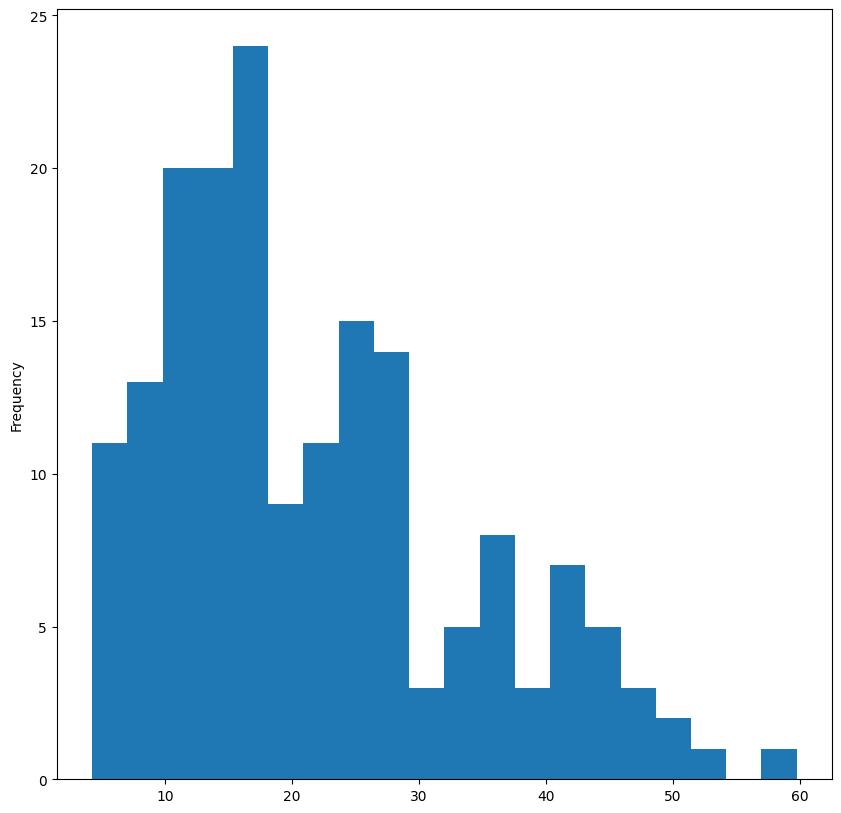

In [33]:
nola_tracts_stats_census["affordability_ratio_CV"].plot.hist(bins = 20)

In [34]:
# flag low-confidence: either infinite CV or CV > 40, if ratio exists
nola_tracts_stats_census["low_confidence"] = (
    nola_tracts_stats_census["affordability_ratio"].notna() & (
        np.isinf(nola_tracts_stats_census["affordability_ratio_CV"]) |
        (nola_tracts_stats_census["affordability_ratio_CV"] > 40)
    )
)

In [35]:
nola_tracts_stats_census.nlargest(5, "affordability_ratio_CV")

,GISJOIN,STATEFP,COUNTYFP,TRACTCE,GEOID,NAME_x,NAMELSAD,MTFCC,FUNCSTAT,ALAND,...,B19013_001E,B19013_001M,state,county,tract,median_daily_income,median_daily_income_M,affordability_ratio,affordability_ratio_CV,low_confidence
23,G2200710000902,22,071,000902,22071000902,9.02,Census Tract 9.02,G5020,S,851301.0,...,51989.0,51087.0,22,071,000902,144.413889,141.908333,NaN,59.735573,False
175,G2200710014101,22,071,014101,22071014101,141.01,Census Tract 141.01,G5020,S,250788.0,...,52992.0,46108.0,22,071,014101,147.200000,128.077778,0.760870,52.893228,True
61,G2200710001900,22,071,001900,22071001900,19,Census Tract 19,G5020,S,398501.0,...,43542.0,36452.0,22,071,001900,120.950000,101.255556,0.711038,50.891715,True
136,G2200710010100,22,071,010100,22071010100,101,Census Tract 101,G5020,S,492234.0,...,74750.0,61434.0,22,071,010100,207.638889,170.650000,0.717592,49.961066,True
135,G2200710010000,22,071,010000,22071010000,100,Census Tract 100,G5020,S,418593.0,...,55938.0,44637.0,22,071,010000,155.383333,123.991667,0.965354,48.508982,True


## Plot

In [36]:
# check crs
nola_tracts_stats_census.crs

<Projected CRS: EPSG:3452>
Name: NAD83 / Louisiana South (ftUS)
Axis Info [cartesian]:
- X[east]: Easting (US survey foot)
- Y[north]: Northing (US survey foot)
Area of Use:
- name: United States (USA) - Louisiana - counties of Acadia; Allen; Ascension; Assumption; Beauregard; Calcasieu; Cameron; East Baton Rouge; East Feliciana; Evangeline; Iberia; Iberville; Jefferson; Jefferson Davis; Lafayette; LaFourche; Livingston; Orleans; Plaquemines; Pointe Coupee; St Bernard; St Charles; St Helena; St James; St John the Baptist; St Landry; St Martin; St Mary; St Tammany; Tangipahoa; Terrebonne; Vermilion; Washington; West Baton Rouge; West Feliciana.
- bounds: (-93.94, 28.85, -88.75, 31.07)
Coordinate Operation:
- name: SPCS83 Louisiana South zone (US survey foot)
- method: Lambert Conic Conformal (2SP)
Datum: North American Datum 1983
- Ellipsoid: GRS 1980
- Prime Meridian: Greenwich

In [37]:
nola_tracts_stats_census.head()

,GISJOIN,STATEFP,COUNTYFP,TRACTCE,GEOID,NAME_x,NAMELSAD,MTFCC,FUNCSTAT,ALAND,...,B19013_001E,B19013_001M,state,county,tract,median_daily_income,median_daily_income_M,affordability_ratio,affordability_ratio_CV,low_confidence
0,G2200710000100,22,071,000100,22071000100,1,Census Tract 1,G5020,S,717245.0,...,92750.0,8807.0,22,071,000100,257.638889,24.463889,0.477412,5.772290,False
1,G2200710000200,22,071,000200,22071000200,2,Census Tract 2,G5020,S,499389.0,...,46602.0,25996.0,22,071,000200,129.450000,72.211111,0.795674,33.910647,False
2,G2200710000300,22,071,000300,22071000300,3,Census Tract 3,G5020,S,634745.0,...,31464.0,10955.0,22,071,000300,87.400000,30.430556,0.961098,21.165696,False
3,G2200710000400,22,071,000400,22071000400,4,Census Tract 4,G5020,S,1496645.0,...,53977.0,15485.0,22,071,000400,149.936111,43.013889,0.780332,17.439602,False
4,G2200710000601,22,071,000601,22071000601,6.01,Census Tract 6.01,G5020,S,485434.0,...,17361.0,9841.0,22,071,000601,48.225000,27.336111,NaN,34.458676,False


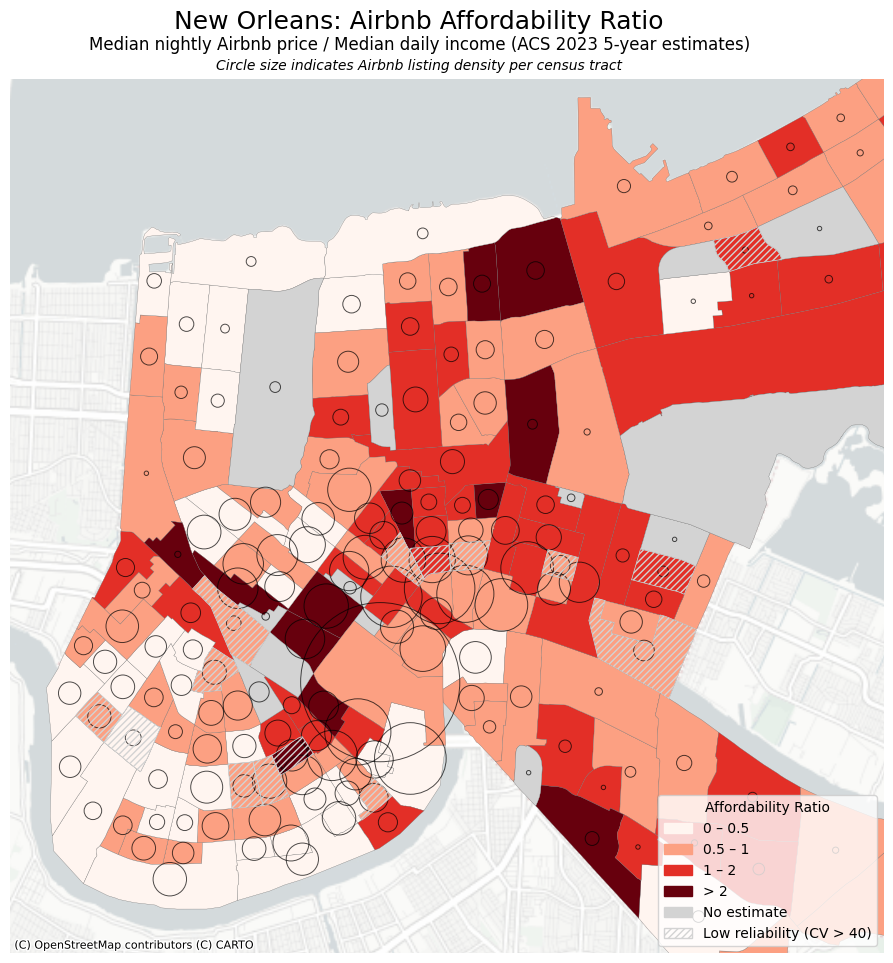

In [38]:
# project both dataframes to web mercator
nola_neighborhoods = nola_neighborhoods.to_crs(epsg=3857)
nola_tracts = nola_tracts.to_crs(epsg=3857)
nola_tracts_stats_census = nola_tracts_stats_census.to_crs(epsg=3857)

# define custom bins
bins = [0, 0.5, 1, 2, nola_tracts_stats_census["affordability_ratio"].max()]

# classify manually
nola_tracts_stats_census["ratio_class"] = pd.cut(
    nola_tracts_stats_census["affordability_ratio"],
    bins=bins,
    labels=["0 – 0.5", "0.5 – 1", "1 – 2", "> 2"],
    include_lowest=True
)

# plot normally (NO scheme)
fig, ax = plt.subplots(1, 1, figsize=(10, 10))

nola_tracts_stats_census.plot(
    column="ratio_class",
    cmap="Reds",
    ax=ax,
    legend=False,   # we build our own
    edgecolor="0.4",
    linewidth=0.2,
    missing_kwds={
        "color": "lightgray",
        "label": "No estimate"
    }
)

# compute centroids
nola_tracts_stats_census["centroid"] = nola_tracts_stats_census.geometry.centroid

# plot Airbnb density circles
ax.scatter(
    nola_tracts_stats_census.centroid.x,
    nola_tracts_stats_census.centroid.y,
    s=nola_tracts_stats_census["airbnb_count"] * 10,  # scale as desired
    facecolor="none",
    edgecolor="black",
    linewidth=0.7,
    alpha=0.7,
    label="Airbnb Count"
)

# neighborhood boundaries: thick
#nola_neighborhoods.boundary.plot(
#    ax=ax, edgecolor="white", linewidth=1
#)

# hatching for low-confidence
nola_tracts_stats_census[nola_tracts_stats_census["low_confidence"]].plot(
    ax=ax, facecolor="none", edgecolor="lightgray", hatch="/////", linewidth=0.5
)

# add basemap
ctx.add_basemap(ax, zoom=12, source=ctx.providers.CartoDB.PositronNoLabels)

# legend
cmap = plt.get_cmap("Reds")

# categories and matching colors in correct order
cats = nola_tracts_stats_census["ratio_class"].cat.categories
colors = [cmap(i / (len(cats)-1)) for i in range(len(cats))]

# build legend handles
handles = [
    mpatches.Patch(color=colors[i], label=str(cats[i]))
    for i in range(len(cats))
]

# missing data
handles.append(mpatches.Patch(color="lightgray", label="No estimate"))

# hatching for low-confidence
handles.append(
    mpatches.Patch(
        facecolor="none",
        edgecolor="lightgray",
        hatch="/////",
        label="Low reliability (CV > 40)"
    )
)

# add legend
ax.legend(handles=handles, title="Affordability Ratio", loc="lower right")

# titles
fig.suptitle("New Orleans: Airbnb Affordability Ratio", fontsize=18, y=1.0)

fig.text(
    0.5, 0.96,
    "Median nightly Airbnb price / Median daily income (ACS 2023 5-year estimates)",
    ha='center', fontsize=12
)

fig.text(
    0.5, 0.94,
    "Circle size indicates Airbnb listing density per census tract",
    ha='center', fontsize=10, style="italic"
)

# Pick a centroid point for the city center
center_point = Point(-90.05774, 29.9785)  # downtown New Orleans in lon/lat
center_point_webmerc = gpd.GeoSeries([center_point], crs="EPSG:4326").to_crs(epsg=3857).iloc[0]

# Define how much to show around it (in meters)
extent = 10000  # half-width / half-height

ax.set_xlim(center_point_webmerc.x - extent, center_point_webmerc.x + extent)
ax.set_ylim(center_point_webmerc.y - extent, center_point_webmerc.y + extent)

plt.tight_layout()
plt.axis("off")

# Save as PNG
plt.savefig(os.path.join(OUTPUT_DIR, "airbnb_affordability_map.png"), dpi=300, bbox_inches="tight")

plt.show()


# Static Map 2: Rental Housing Unit Gap + Flood Risk
---
New Orleans has massive spatial inequality

Overlaying housing shortage with flood risk is a way to show misalignment between housing need and environmental vulnerability

*   Choropleth: Rental housing gap per tract (undersupply → darker red)
*   Overlay (hatching): Flood zone or % area in FEMA special flood hazard


## Import & clean data

In [39]:
rental_housing_gap_df = pd.read_csv(os.path.join(DATA_DIR, "PolicyMap Data 2025-11-21 152011 UTC.csv"))

rental_housing_gap_df = rental_housing_gap_df.drop(index=0).reset_index(drop=True)

rental_housing_gap_df.head()

,Geography Type Description,Geography Name,Sits in State,GeoID,Formatted GeoID,Total Rental Housing Unit Gap: Severity,Data Time Period,Geographic Vintage,Data Source,Selected Location
0,Census Tract,22071000100,LA,22071000100,"=""22071000100""",Substantially Undersupplied (-5% and less),2019-2023,2022,"Moody's Analytics, Reinvestment Fund, and Poli...","New Orleans (City, 2020)"
1,Census Tract,22071000200,LA,22071000200,"=""22071000200""",Substantially Undersupplied (-5% and less),2019-2023,2022,"Moody's Analytics, Reinvestment Fund, and Poli...","New Orleans (City, 2020)"
2,Census Tract,22071000300,LA,22071000300,"=""22071000300""",Modestly Oversupplied (+2% to +4.99%),2019-2023,2022,"Moody's Analytics, Reinvestment Fund, and Poli...","New Orleans (City, 2020)"
3,Census Tract,22071000400,LA,22071000400,"=""22071000400""",Close to Balanced (-1.99% to +1.99%),2019-2023,2022,"Moody's Analytics, Reinvestment Fund, and Poli...","New Orleans (City, 2020)"
4,Census Tract,22071000601,LA,22071000601,"=""22071000601""",Modestly Undersupplied (-4.99% to -2%),2019-2023,2022,"Moody's Analytics, Reinvestment Fund, and Poli...","New Orleans (City, 2020)"


In [40]:
# join with tract to get geometry and make a geodataframe
print(rental_housing_gap_df.dtypes)
print(nola_tracts.dtypes)

Geography Type Description                 object
Geography Name                             object
Sits in State                              object
GeoID                                      object
Formatted GeoID                            object
Total Rental Housing Unit Gap: Severity    object
Data Time Period                           object
Geographic Vintage                         object
Data Source                                object
Selected Location                          object
dtype: object
GISJOIN         object
STATEFP         object
COUNTYFP        object
TRACTCE         object
GEOID           object
NAME            object
NAMELSAD        object
MTFCC           object
FUNCSTAT        object
ALAND          float64
AWATER         float64
INTPTLAT        object
INTPTLON        object
Shape_Leng     float64
Shape_Area     float64
geometry      geometry
dtype: object


In [41]:
print(rental_housing_gap_df["GeoID"])
print(nola_tracts["GEOID"])

0      22071000100
1      22071000200
2      22071000300
3      22071000400
4      22071000601
          ...     
179    22071014400
180    22071014500
181    22071980000
182    22071980100
183    22071990000
Name: GeoID, Length: 184, dtype: object
33646    22071000100
33647    22071000200
33648    22071000300
33649    22071000400
33650    22071000601
            ...     
33824    22071014300
33825    22071014400
33826    22071014500
33827    22071980000
33828    22071980100
Name: GEOID, Length: 183, dtype: object


In [42]:
rental_gap_tracts_df = rental_housing_gap_df.merge(nola_tracts, left_on="GeoID", right_on="GEOID", how="inner")

rental_gap_tracts_df.head()

,Geography Type Description,Geography Name,Sits in State,GeoID,Formatted GeoID,Total Rental Housing Unit Gap: Severity,Data Time Period,Geographic Vintage,Data Source,Selected Location,...,NAMELSAD,MTFCC,FUNCSTAT,ALAND,AWATER,INTPTLAT,INTPTLON,Shape_Leng,Shape_Area,geometry
0,Census Tract,22071000100,LA,22071000100,"=""22071000100""",Substantially Undersupplied (-5% and less),2019-2023,2022,"Moody's Analytics, Reinvestment Fund, and Poli...","New Orleans (City, 2020)",...,Census Tract 1,G5020,S,717245.0,505586.0,+29.9532061,-090.0521978,4606.405929,1.222833e+06,"POLYGON ((-10023890.23 3496951.371, -10023993...."
1,Census Tract,22071000200,LA,22071000200,"=""22071000200""",Substantially Undersupplied (-5% and less),2019-2023,2022,"Moody's Analytics, Reinvestment Fund, and Poli...","New Orleans (City, 2020)",...,Census Tract 2,G5020,S,499389.0,167245.0,+29.9459372,-090.0528397,4055.663337,6.666407e+05,"POLYGON ((-10023890.23 3496951.371, -10023784...."
2,Census Tract,22071000300,LA,22071000300,"=""22071000300""",Modestly Oversupplied (+2% to +4.99%),2019-2023,2022,"Moody's Analytics, Reinvestment Fund, and Poli...","New Orleans (City, 2020)",...,Census Tract 3,G5020,S,634745.0,0.0,+29.9409498,-090.0489913,3610.964402,6.347467e+05,"POLYGON ((-10024074.241 3495174.568, -10024200..."
3,Census Tract,22071000400,LA,22071000400,"=""22071000400""",Close to Balanced (-1.99% to +1.99%),2019-2023,2022,"Moody's Analytics, Reinvestment Fund, and Poli...","New Orleans (City, 2020)",...,Census Tract 4,G5020,S,1496645.0,200524.0,+29.9468233,-090.0425280,7749.801050,1.697170e+06,"POLYGON ((-10023381.834 3498088.419, -10022992..."
4,Census Tract,22071000601,LA,22071000601,"=""22071000601""",Modestly Undersupplied (-4.99% to -2%),2019-2023,2022,"Moody's Analytics, Reinvestment Fund, and Poli...","New Orleans (City, 2020)",...,Census Tract 6.01,G5020,S,485434.0,0.0,+29.9327828,-090.0409526,2916.366439,4.854390e+05,"POLYGON ((-10023342.872 3495531.681, -10023291..."


In [43]:
rental_gap_tracts_df.shape

(183, 26)

In [44]:
rental_gap_tracts_df["Total Rental Housing Unit Gap: Severity"].value_counts()

,count
Total Rental Housing Unit Gap: Severity,
Substantially Undersupplied (-5% and less),71
Modestly Undersupplied (-4.99% to -2%),36
Close to Balanced (-1.99% to +1.99%),32
Substantially Oversupplied (+5% or more),23
Modestly Oversupplied (+2% to +4.99%),17


In [45]:
# convert to geodataframe
rental_gap_tracts = gpd.GeoDataFrame(
    rental_gap_tracts_df,
    geometry="geometry",
    crs=nola_tracts.crs
)
rental_gap_tracts.head()

,Geography Type Description,Geography Name,Sits in State,GeoID,Formatted GeoID,Total Rental Housing Unit Gap: Severity,Data Time Period,Geographic Vintage,Data Source,Selected Location,...,NAMELSAD,MTFCC,FUNCSTAT,ALAND,AWATER,INTPTLAT,INTPTLON,Shape_Leng,Shape_Area,geometry
0,Census Tract,22071000100,LA,22071000100,"=""22071000100""",Substantially Undersupplied (-5% and less),2019-2023,2022,"Moody's Analytics, Reinvestment Fund, and Poli...","New Orleans (City, 2020)",...,Census Tract 1,G5020,S,717245.0,505586.0,+29.9532061,-090.0521978,4606.405929,1.222833e+06,"POLYGON ((-10023890.23 3496951.371, -10023993...."
1,Census Tract,22071000200,LA,22071000200,"=""22071000200""",Substantially Undersupplied (-5% and less),2019-2023,2022,"Moody's Analytics, Reinvestment Fund, and Poli...","New Orleans (City, 2020)",...,Census Tract 2,G5020,S,499389.0,167245.0,+29.9459372,-090.0528397,4055.663337,6.666407e+05,"POLYGON ((-10023890.23 3496951.371, -10023784...."
2,Census Tract,22071000300,LA,22071000300,"=""22071000300""",Modestly Oversupplied (+2% to +4.99%),2019-2023,2022,"Moody's Analytics, Reinvestment Fund, and Poli...","New Orleans (City, 2020)",...,Census Tract 3,G5020,S,634745.0,0.0,+29.9409498,-090.0489913,3610.964402,6.347467e+05,"POLYGON ((-10024074.241 3495174.568, -10024200..."
3,Census Tract,22071000400,LA,22071000400,"=""22071000400""",Close to Balanced (-1.99% to +1.99%),2019-2023,2022,"Moody's Analytics, Reinvestment Fund, and Poli...","New Orleans (City, 2020)",...,Census Tract 4,G5020,S,1496645.0,200524.0,+29.9468233,-090.0425280,7749.801050,1.697170e+06,"POLYGON ((-10023381.834 3498088.419, -10022992..."
4,Census Tract,22071000601,LA,22071000601,"=""22071000601""",Modestly Undersupplied (-4.99% to -2%),2019-2023,2022,"Moody's Analytics, Reinvestment Fund, and Poli...","New Orleans (City, 2020)",...,Census Tract 6.01,G5020,S,485434.0,0.0,+29.9327828,-090.0409526,2916.366439,4.854390e+05,"POLYGON ((-10023342.872 3495531.681, -10023291..."


In [46]:
zip_path = os.path.join(DATA_DIR, "fema_flood.zip")

# List layers
flood_gdf = gpd.read_file(f"zip://{zip_path}!S_FLD_HAZ_AR.shp")

flood_gdf.head()

,DFIRM_ID,VERSION_ID,FLD_AR_ID,STUDY_TYP,FLD_ZONE,ZONE_SUBTY,SFHA_TF,STATIC_BFE,V_DATUM,DEPTH,LEN_UNIT,VELOCITY,VEL_UNIT,AR_REVERT,AR_SUBTRV,BFE_REVERT,DEP_REVERT,DUAL_ZONE,SOURCE_CIT,geometry
0,22071C,1.1.1.0,22071C_150,NP,X,0.2 PCT ANNUAL CHANCE FLOOD HAZARD,F,-9999.0,None,-9999.0,None,-9999.0,None,None,None,-9999.0,-9999.0,None,22071C_STUDY13,"POLYGON ((-90.12141 29.99395, -90.12141 29.993..."
1,22071C,1.1.1.0,22071C_151,NP,X,0.2 PCT ANNUAL CHANCE FLOOD HAZARD,F,-9999.0,None,-9999.0,None,-9999.0,None,None,None,-9999.0,-9999.0,None,22071C_STUDY13,"POLYGON ((-90.03497 29.99339, -90.03497 29.993..."
2,22071C,1.1.1.0,22071C_152,NP,X,0.2 PCT ANNUAL CHANCE FLOOD HAZARD,F,-9999.0,None,-9999.0,None,-9999.0,None,None,None,-9999.0,-9999.0,None,22071C_STUDY13,"POLYGON ((-90.04161 29.99378, -90.04161 29.993..."
3,22071C,1.1.1.0,22071C_153,NP,X,0.2 PCT ANNUAL CHANCE FLOOD HAZARD,F,-9999.0,None,-9999.0,None,-9999.0,None,None,None,-9999.0,-9999.0,None,22071C_STUDY13,"POLYGON ((-90.04867 29.9939, -90.04866 29.9939..."
4,22071C,1.1.1.0,22071C_154,NP,X,0.2 PCT ANNUAL CHANCE FLOOD HAZARD,F,-9999.0,None,-9999.0,None,-9999.0,None,None,None,-9999.0,-9999.0,None,22071C_STUDY13,"POLYGON ((-90.03875 29.99369, -90.03875 29.993..."


In [68]:
# replace -9999 with NA
flood_gdf.replace(-9999, np.nan, inplace=True)

# change to web mercator
flood_gdf = flood_gdf.to_crs(epsg=3857)

# filter for SFHA (special flood hazard areas)
sfha = flood_gdf[flood_gdf["SFHA_TF"] == "T"]

# filter for severe flood areas only
# V: Coastal areas with a 1% or greater chance of flooding and with the additional hazard of storm waves
sfha_v = sfha[sfha["FLD_ZONE"].isin(["V", "VE"])]
# A: Areas with a 1% annual chance of flooding, and therefore a 25% chance over the life of a 30-year mortgage
sfha_a = sfha[sfha["FLD_ZONE"].isin(["A", "AE", "AO", "AH"])]

sfha_v = sfha_v[sfha_v.geometry.area > 1000]  # area threshold in square meters
sfha_a = sfha_a[sfha_a.geometry.area > 1000]

# Dissolve first
sfha_v_dissolved = sfha_v.dissolve()
sfha_a_dissolved = sfha_a.dissolve()

# Simplify geometry (adjust tolerance as needed)
sfha_v_simpl = sfha_v_dissolved.simplify(tolerance=200)  # in meters for EPSG:3857
sfha_a_simpl = sfha_a_dissolved.simplify(tolerance=200)

# Extract boundaries for plotting
sfha_v_outline = sfha_v_simpl.boundary
sfha_a_outline = sfha_a_simpl.boundary

## Plot

In [48]:
# Check what’s in the column
print(rental_gap_tracts["Total Rental Housing Unit Gap: Severity"].unique())

# Count non-null values
print(rental_gap_tracts["Total Rental Housing Unit Gap: Severity"].notna().sum())

['Substantially Undersupplied (-5% and less)'
 'Modestly Oversupplied (+2% to +4.99%)'
 'Close to Balanced (-1.99% to +1.99%)'
 'Modestly Undersupplied (-4.99% to -2%)'
 'Substantially Oversupplied (+5% or more)' nan]
179


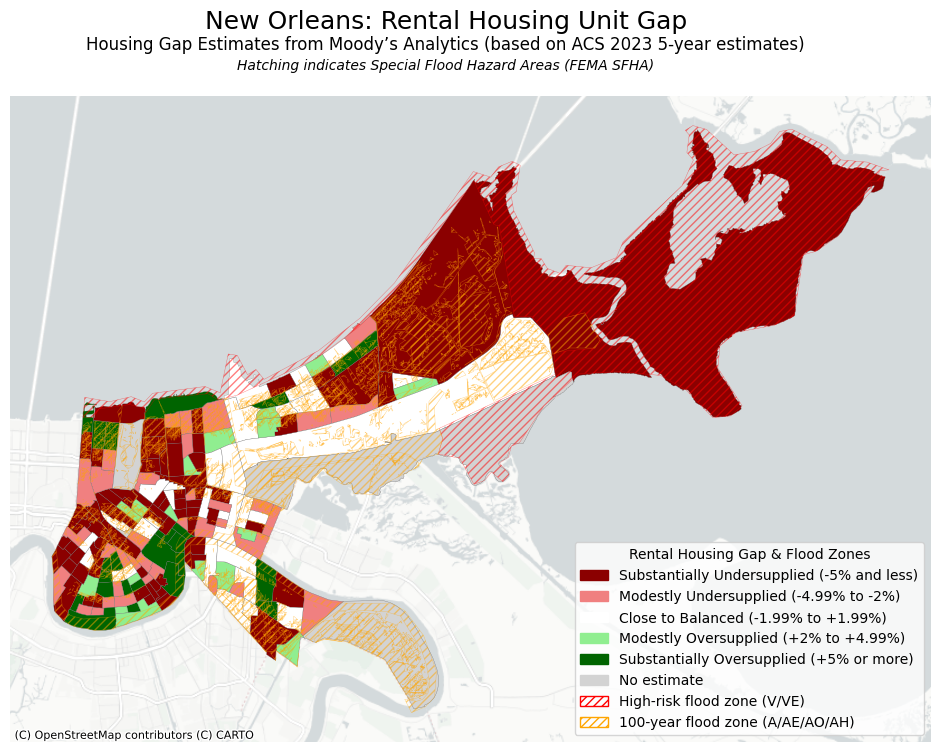

In [69]:
# standardize category labels so they match the ordered categories below
rental_gap_tracts["Total Rental Housing Unit Gap: Severity"] = rental_gap_tracts[
    "Total Rental Housing Unit Gap: Severity"
].replace({
    "Modestly undersupplied (-4.99% to -2%)": "Modestly Undersupplied (-4.99% to -2%)",
    "Close to balance (-1.99% to +1.99%)": "Close to Balanced (-1.99% to +1.99%)",
    "Modestly oversupplied (+2% to +4.99%)": "Modestly Oversupplied (+2% to +4.99%)",
    "Substantially oversupplied (+5% or more)": "Substantially Oversupplied (+5% or more)",
    "Substantially undersupplied (-5% and less)": "Substantially Undersupplied (-5% and less)"
})

# Make sure categories exist in the data
correct_order = [
    "Substantially Undersupplied (-5% and less)",
    "Modestly Undersupplied (-4.99% to -2%)",
    "Close to Balanced (-1.99% to +1.99%)",
    "Modestly Oversupplied (+2% to +4.99%)",
    "Substantially Oversupplied (+5% or more)"
]

rental_gap_tracts["Total Rental Housing Unit Gap: Severity"] = pd.Categorical(
    rental_gap_tracts["Total Rental Housing Unit Gap: Severity"],
    categories=correct_order,
    ordered=True
)

# plot
fig, ax = plt.subplots(1, 1, figsize=(10, 10))

# Define colors for 5 categories (green -> white -> red)
color_list = ["darkred", "lightcoral", "white", "lightgreen", "darkgreen"]
cmap = mcolors.ListedColormap(color_list)


# base choropleth
rental_gap_tracts.plot(
    column="Total Rental Housing Unit Gap: Severity",
    categorical=True,
    legend=False,
    cmap=cmap,
    ax=ax,
    edgecolor="0.4",
    linewidth=0.2,
    missing_kwds={"color": "lightgray", "label": "No estimate"}
)

# V flood zones
sfha_v_outline.plot(
    ax=ax,
    facecolor="none",
    edgecolor="red",
    linewidth=0.3,
    hatch="////",
    alpha=0.5
)

# A flood zones
sfha_a_outline.plot(
    ax=ax,
    facecolor="none",
    edgecolor="orange",
    linewidth=0.3,
    hatch="////",
    alpha=0.5
)

# Choropleth legend items

categories = rental_gap_tracts["Total Rental Housing Unit Gap: Severity"].cat.categories
colors = [cmap(i / (len(categories) - 1)) for i in range(len(categories))]

choropleth_handles = [mpatches.Patch(color=colors[i], label=categories[i]) for i in range(len(categories))]

# Missing-data patch
choropleth_handles.append(
    mpatches.Patch(color="lightgray", label="No estimate")
)

# Flood-zone hatched legend items
hatch_V = mpatches.Patch(
    facecolor="none", edgecolor="red", hatch="////",
    label="High-risk flood zone (V/VE)"
)
hatch_A = mpatches.Patch(
    facecolor="none", edgecolor="orange", hatch="////",
    label="100-year flood zone (A/AE/AO/AH)"
)

# Combine everything
all_handles = choropleth_handles + [hatch_V, hatch_A]

# Final legend
ax.legend(
    handles=all_handles,
    title="Rental Housing Gap & Flood Zones",
    loc="lower right"
)

ctx.add_basemap(ax, source=ctx.providers.CartoDB.PositronNoLabels)

# titles
fig.suptitle("New Orleans: Rental Housing Unit Gap", fontsize=18, y=0.89)

fig.text(
    0.5, 0.85,
    "Housing Gap Estimates from Moody’s Analytics (based on ACS 2023 5-year estimates)",
    ha='center', fontsize=12
)

fig.text(
    0.5, 0.83,
    "Hatching indicates Special Flood Hazard Areas (FEMA SFHA)",
    ha='center', fontsize=10, style="italic"
)

plt.tight_layout()
ax.set_axis_off()

# Save as PNG
plt.savefig(os.path.join(OUTPUT_DIR, "airbnb_housinggap_map.png"), dpi=300, bbox_inches="tight")

plt.show()


# Interactive Map

## Import data

In [50]:
rta_routes_df = pd.read_csv(os.path.join(DATA_DIR, "RTA_Routes.csv"))

# convert WKT strings to shapely geometry
rta_routes_df["geometry"] = rta_routes_df["the_geom"].apply(wkt.loads)

# create geodataframe
rta_routes = gpd.GeoDataFrame(
    rta_routes_df,
    geometry="geometry",
    crs="EPSG:4326"
)
rta_routes.head()

,the_geom,OBJECTID,Shape.STLength(),shape_id,route_id,agency_id,route_short_name,route_long_name,route_desc,route_type,route_url,route_color,route_text_color,route_type_text,geometry
0,MULTILINESTRING ((-90.043988608026 30.02321043...,75,70056.658033,shp-57-02,57,1.0,57,Franklin-Freret,NaN,3.0,NaN,d6ed6b,0000ff,Bus,"MULTILINESTRING ((-90.04399 30.02321, -90.0439..."
1,MULTILINESTRING ((-90.070066612159 29.95353541...,27,35782.476550,shp-12-55,12,1.0,12,St. Charles Streetcar,NaN,0.0,NaN,006737,ffffff,"Tram, Streetcar, Light rail","MULTILINESTRING ((-90.07007 29.95354, -90.0700..."
2,MULTILINESTRING ((-90.110075623437 29.96540041...,68,57048.439786,shp-52-55,52,1.0,52,Paris-Broadmoor,NaN,3.0,NaN,99aad1,000000,Bus,"MULTILINESTRING ((-90.11008 29.9654, -90.10993..."
3,MULTILINESTRING ((-90.25572366429 29.996598417...,28,82185.657237,shp-202-03,202,1.0,202,Airport Express,NaN,3.0,NaN,ff00ff,0000ff,Bus,"MULTILINESTRING ((-90.25572 29.9966, -90.25572..."
4,MULTILINESTRING ((-90.090040618848 29.98385841...,56,4919.939537,shp-48-12,48,1.0,48,Canal Streetcar - City Park/Muse,NaN,0.0,NaN,87cb25,000000,"Tram, Streetcar, Light rail","MULTILINESTRING ((-90.09004 29.98386, -90.0901..."


In [51]:
# Ensure route_color starts with "#"
rta_routes["route_text_color"] = rta_routes["route_text_color"].apply(
    lambda x: f"#{x}" if isinstance(x, str) and not x.startswith("#") else x
)

In [52]:
rta_stops_df = pd.read_csv(os.path.join(DATA_DIR, "RTA_Stops_20251202.csv"))

# convert the WKT POINT column into shapely geometry
rta_stops_df["geometry"] = rta_stops_df["the_geom"].apply(wkt.loads)

# create geodataframe
rta_stops = gpd.GeoDataFrame(
    rta_stops_df,
    geometry="geometry",
    crs="EPSG:4326"
)
rta_stops.head()

,OBJECTID,the_geom,stop_id,stop_code,stop_name,stop_desc,stop_lat,stop_lon,zone_id,stop_url,location_type,parent_station,stop_timezone,wheelchair_boarding,geometry
0,"1,819",POINT (-90.041184603639 29.937256411381),2054,8306,L B Landry at Mardi Gras,NaN,29.937251,-90.041179,NaN,NaN,NaN,NaN,NaN,2,POINT (-90.04118 29.93726)
1,"1,509",POINT (-90.092055618696 29.968723416556),1660,5523,Canal + Lopez (Out),NaN,29.968718,-90.092050,NaN,NaN,NaN,NaN,NaN,2,POINT (-90.09206 29.96872)
2,"1,055",POINT (-90.050293608974 30.005168425948),289,1377,Franklin Ave. at Lombard St.,NaN,30.005163,-90.050288,NaN,NaN,NaN,NaN,NaN,2,POINT (-90.05029 30.00517)
3,"1,727",POINT (-90.113639625049 29.981024418534),1929,798,Metairie Rd. + Pontchartrain (RIVERSIDE),NaN,29.981019,-90.113634,NaN,NaN,NaN,NaN,NaN,2,POINT (-90.11364 29.98102)
4,476,POINT (-90.103877620725 29.942302410446),1360,3773,Napoleon at S. Roman,NaN,29.942297,-90.103872,NaN,NaN,NaN,NaN,NaN,2,POINT (-90.10388 29.9423)


## Make buffers

In [53]:
rta_stops_lasp = rta_stops.to_crs(epsg=3452) # convert to LA State Plane for buffer
rta_stops_lasp_quarter_mile_buffer = rta_stops_lasp.buffer(1320) # Do a quarter-mile buffer
rta_stops_lasp_quarter_mile_buffer_gdf = gpd.GeoDataFrame(index=[0], crs='epsg:3452', geometry=[rta_stops_lasp_quarter_mile_buffer.union_all()])
rta_stops_lasp_quarter_mile_buffer_gdf_webm = rta_stops_lasp_quarter_mile_buffer_gdf.to_crs(epsg=4326) # convert back to WGS84 (lat/lon) for Folium

## Build Folium Map

In [54]:
nola_tracts_stats_census.dtypes

,0
GISJOIN,object
STATEFP,object
COUNTYFP,object
TRACTCE,object
GEOID,object
NAME_x,object
NAMELSAD,object
MTFCC,object
FUNCSTAT,object
ALAND,float64


In [55]:
# Create empty map (no tiles)
m = folium.Map(location=[29.9509, -90.0758], tiles=None, zoom_start=11, height=850, width="100%")

# Basemaps
folium.TileLayer(
    tiles="CartoDB positron",
    name="Carto Positron",
    control=True,
    show=True
).add_to(m)

folium.TileLayer("OpenStreetMap", name="OpenStreetMap", control=True, show=False).add_to(m)

# Affordability Ratio Choropleth
tracts_4326 = nola_tracts_stats_census.to_crs(epsg=4326)
# Keep only the geometry you want for the choropleth
tracts_4326_polygons = tracts_4326[['GEOID', 'affordability_ratio', 'geometry']]
# convert to GeoJSON
geo = tracts_4326_polygons.to_json()

# Add the choropleth
folium.Choropleth(
    geo_data=geo,
    data=tracts_4326_polygons,
    name="Affordability Ratio Choropleth",
    columns=["GEOID", "affordability_ratio"],
    key_on="feature.properties.GEOID",
    fill_color="YlGn",
    fill_opacity=0.7,
    line_opacity=0.2,
    legend_name="Affordability Ratio (ACS 2023)",
).add_to(m)

# Airbnb marker cluster
airbnb_layer = plugins.MarkerCluster(name="Airbnb Listings", control=True).add_to(m)

for idx, airbnb in nola_airbnbs.iterrows():
    # Custom color
    if airbnb['room_type'] == "Entire home/apt":
        type_color = "green"
    elif airbnb['room_type'] == "Private room":
        type_color = "blue"
    elif airbnb['room_type'] == "Shared room":
        type_color = "orange"
    else:
        type_color = "red"

    popup_text = (f"<b>Name:</b> {airbnb['name']}<br>"
                  f"<b>Room Type:</b> {airbnb['room_type']}<br>"
                  f"<b>Price:</b> ${airbnb['price']}<br>"
                  f"<b>Number of Reviews:</b> {airbnb['number_of_reviews']}<br>"
                  f"<b>Availability (out of 365 days):</b> {airbnb['availability_365']}")

    folium.Marker(
        location=[airbnb.geometry.y, airbnb.geometry.x],
        popup=folium.Popup(
            popup_text,
            max_width=len(f"Name= {airbnb['room_type']}")*20),
        icon=folium.Icon(color=type_color, icon="home", prefix="fa"),
    ).add_to(airbnb_layer)

# Heatmap Layer
heatmappane = folium.map.CustomPane('heatmappane', z_index=400)
m.add_child(heatmappane)

airbnb_locations = [[point.y, point.x] for point in nola_airbnbs.geometry]
plugins.HeatMap(airbnb_locations, pane='heatmappane',
                radius = 20, blur = 25,
                gradient={.4: "blue", .6: "cyan", .7: "lime", .8: "yellow", 1: "red"},
                name = "Airbnb Heat Map").add_to(m)

# Add flood zones
sfha_simplified = sfha.to_crs(4326).copy()
sfha_simplified["geometry"] = sfha_simplified.geometry.simplify(
    tolerance=0.0005,      # adjust as needed (higher = more simplified)
    preserve_topology=True
)

flood_group = folium.FeatureGroup(name="Flood Zones (SFHA)", show=True)

# For example, overlay SFHA zones with hatching or color
folium.GeoJson(
    sfha_simplified,
    style_function=lambda feature: {
        "fillColor": "red" if feature['properties']['FLD_ZONE'] in ['V','VE'] else "orange",
        "color": "black",
        "weight": 1,
        "fillOpacity": 0.3,
        "dashArray": "5, 5"  # optional for hatch-like effect
    },
    tooltip=folium.GeoJsonTooltip(
        fields=["FLD_ZONE", "ZONE_SUBTY"],
        aliases=["Zone:", "Subtype:"]
    )
).add_to(flood_group)

flood_group.add_to(m)

# Add public transit buffers
transit_buffers = folium.FeatureGroup(name='Quarter-mile Buffer',control=True)

for _, r in rta_stops_lasp_quarter_mile_buffer_gdf_webm.iterrows():
    # simplify geometry so the map renders smoothly
    sim_geo = gpd.GeoSeries(r['geometry']).simplify(tolerance=.0000001)
    geo_j = sim_geo.to_json()
    geo_j = folium.GeoJson(data=geo_j,
                           style_function=lambda x: {'fillColor': 'white', # fill color
                                                     'color': 'black', # line color
                                                     'weight': 2}) # line width (look at Folium docs to see the other parameters you can pass here)
    geo_j.add_to(transit_buffers)

transit_buffers.add_to(m)

# Add public transit routes
folium.GeoJson(
    rta_routes,
    name="Transit Routes",
    style_function=lambda feature: {
        "color": feature["properties"]["route_text_color"],
        "weight": 3,
        "opacity": 0.8
    },
    tooltip=folium.GeoJsonTooltip(
        fields=["route_short_name", "route_long_name", "route_type_text"],
        aliases=["Route:", "Name:", "Type:"],
    )
).add_to(m)

# Add public transit stops
pt_pane = folium.map.CustomPane('pt_pane', z_index=700)
m.add_child(pt_pane)

pt_layer = folium.FeatureGroup(name="RTA Stops")

for idx, station in rta_stops.iterrows():
    folium.CircleMarker(
        location=[station.geometry.y, station.geometry.x],
        pane="pt_pane",
        radius=5,
        color="black",
        fill=True,
        fill_color="black",
        fill_opacity=0.7,
        tooltip=f"Station: {station['stop_name']}"
    ).add_to(pt_layer)

pt_layer.add_to(m)

# Add Layer control
folium.LayerControl().add_to(m)

m

Output hidden; open in https://colab.research.google.com to view.

In [56]:
m.save(os.path.join(OUTPUT_DIR, 'nola_Airbnbs.html'))